# Sisal port bathymetry, 24 Sep and 16 Oct 2026

Processing of the two bathymetry surveys we did in the port of Sisal.

- **24 Sep**: Odom Echotrac MKIII (.dso files) + GPS track in the xlsx. Tide from the Sisal gauge csv (15 min), `marea` is already relative to MSL.
- **16 Oct**: Hypack edited files (.EDT), positions are already in there. Tide from the gauge txt file (1 min), subtract 1.9 m to get MSL 2026.

Depth on the maps = measured depth - tide, so both surveys are in depth below MSL 2026 and can be compared.
Background is the satellite image with the drone photo on top.

All paths are relative to this notebook: input data is in `data/`, everything the notebook makes goes to `output/`.

## Settings

In [1]:
# output folder for the figures (csv files go to output/)
FIG_DIR    = "output/figures"

# 24 Sep survey
SEP_DSO_GLOB   = "data/survey_24sep2026/DSO/*.dso"
SEP_SKIP_FILES = ["MK3_2026_09_24_14_17_00.dso"]   # test recording
SEP_GPS_FILE   = "data/survey_24sep2026/Bati240926.xlsx"
SEP_TIDE_FILE  = "data/tide/260626-260930.csv"
SEP_TIDE_OFFSET_M = 0.0        # csv is already relative to MSL
SEP_OUT_CSV    = "output/Bathymetry_Port_Sisal_24sep2026.csv"
SEP_OUT_PNG    = "output/figures/bathymetry_map_24sep2026.png"

# 16 Oct survey
OCT_EDT_GLOB   = "data/survey_16oct2026/*.EDT"
OCT_SKIP_FILES = []
OCT_TIDE_FILE  = "data/tide/20261016al18_sisal.txt"   # None if no tide data
OCT_TIDE_OFFSET_M = 1.9        # MSL 2026 in the gauge readings
OCT_WATER_LEVEL_DROP_M = 0.0375   # only used when there is no tide file
OCT_OUT_CSV    = "output/Bathymetry_Port_Sisal_16oct2026.csv"
OCT_OUT_PNG    = "output/figures/bathymetry_map_16oct2026.png"

# comparison
COMPARE_PNG    = "output/figures/bathymetry_24sep_vs_16oct.png"
DIFF_PNG       = "output/figures/bathymetry_difference_16oct_minus_24sep.png"
DIFF_CSV       = "output/bathymetry_difference_16oct_minus_24sep.csv"
DIFF_CELL_M    = 2.0        # grid size for the difference
DIFF_LIMIT_M   = 0.5

# echo sounder processing
CHANNEL         = 1        # channel 2 is noisier
DEPTH_SCALE_M   = 0.01     # cm to m
TIME_OFFSET_S   = 0.0
DESPIKE_WINDOW  = 41
DESPIKE_LIMIT_M = 0.30
BIN_SECONDS     = 0.5
TIDE_SMOOTH_MIN = 5

# maps
EPSG          = 32615      # UTM 15N
USE_SATELLITE = True
# The original drone tif (~700 MB) is too big for the repository, so a resampled copy is
# stored in data/drone/ and used instead. Set DRONE_TIF to the tif to rebuild it.
DRONE_TIF     = None
DRONE_DATE    = "2026-10-07"   # date of the drone photo
DRONE_PIXEL_M = 0.1
DRONE_CACHE   = f"data/drone/drone_background_{EPSG}_{DRONE_PIXEL_M}m.npz"
COLOR_MIN_M   = 0.5
COLOR_MAX_M   = 4.5
POINT_SIZE    = 6

In [2]:
import glob, os, struct
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

os.makedirs(FIG_DIR, exist_ok=True)

## Tide

Same function for both surveys. Reads the gauge csv (24 Sep), the old xlsx or the gauge txt (16 Oct) and interpolates the tide to the sounding times.

In [3]:
def tide_at(times, tide_file, offset=0.0):
    if tide_file is None:
        return np.zeros(len(times))
    if tide_file.lower().endswith(".txt"):
        raw = pd.read_csv(tide_file, sep=r"\s+", header=None, names=["Y", "M", "D", "h", "m", "s", "level"])
        tide = pd.DataFrame({"time": pd.to_datetime(dict(year=raw.Y, month=raw.M, day=raw.D,
                                                          hour=raw.h, minute=raw.m, second=raw.s)),
                             "tide": raw["level"] - offset})
    elif tide_file.lower().endswith(".csv"):
        raw = pd.read_csv(tide_file)
        tide = pd.DataFrame({"time": pd.to_datetime(raw["fecha"] + " " + raw["tiempo"], format="%m/%d/%Y %H:%M:%S"),
                             "tide": pd.to_numeric(raw["marea"], errors="coerce") - offset}).dropna()
    else:
        tide = pd.read_excel(tide_file, header=1)
        tide = pd.DataFrame({"time": pd.to_datetime(tide["date"]),
                             "tide": pd.to_numeric(tide["tide"], errors="coerce") - offset}).dropna()
    tide = tide.sort_values("time").set_index("time")
    smooth = tide["tide"].rolling(f"{TIDE_SMOOTH_MIN}min", center=True, min_periods=1).mean()
    if times.min() < tide.index.min() or times.max() > tide.index.max():
        print("WARNING: the tide record does not cover the whole survey")
    t0 = tide.index[0]
    return np.interp((times - t0).dt.total_seconds(), (tide.index - t0).total_seconds(), smooth)

## 24 Sep survey

The .dso files are binary. Each record is a 4 byte prefix, 23 byte timestamp, 4 byte length N, a tag like `#MK3,1,M` and then the payload. The next record starts 32 + N bytes later. For the pings the depth in cm is a big-endian uint16 at byte 11 of the payload.

The clock of the sounder was wrong (and 12h format), so only the time since the first ping is used and that is matched to the first GPS point.

In [4]:
def read_dso(path):
    d = open(path, "rb").read()
    rows, pos = [], 0
    while pos + 32 <= len(d):
        n = struct.unpack("<I", d[pos+28:pos+32])[0]
        if n < 10 or pos + 32 + n > len(d):
            break
        end = d.find(b"\x00", pos+32, pos+32+n)
        parts = d[pos+32:end].decode("latin1").split(",")
        if len(parts) >= 2 and parts[1] in ("1", "2"):
            payload = d[end+1:pos+32+n]
            rows.append((d[pos+4:pos+27].decode("latin1"), int(parts[1]),
                         struct.unpack(">H", payload[11:13])[0]))
        pos += 32 + n
    df = pd.DataFrame(rows, columns=["clock", "channel", "depth_raw"])
    df["time"] = pd.to_datetime(df["clock"], format="%d.%m.%Y %H.%M.%S.%f")
    return df


# some files are duplicates of the same recording, skip those
parts, seen = [], set()
for f in sorted(glob.glob(SEP_DSO_GLOB)):
    if os.path.basename(f) in SEP_SKIP_FILES:
        continue
    df = read_dso(f)
    if df.empty or df["clock"].iloc[0] in seen:
        print("skipped:", os.path.basename(f)); continue
    seen.add(df["clock"].iloc[0])
    parts.append(df)
echo = pd.concat(parts, ignore_index=True)

# fix the 12h clock
fixed, wrap, prev = [], pd.Timedelta(0), echo["time"].iloc[0]
for v in echo["time"]:
    if v + wrap < prev - pd.Timedelta(hours=6):
        wrap += pd.Timedelta(hours=12)
    prev = v + wrap
    fixed.append(prev)
echo["t_s"] = (pd.Series(fixed) - fixed[0]).dt.total_seconds() + TIME_OFFSET_S

# GPS, only the survey points (S0...)
gps = pd.read_excel(SEP_GPS_FILE, header=1)
gps = gps[gps["Description"].astype(str).str.startswith("S0")]
gps = pd.DataFrame({"time": pd.to_datetime(gps[gps.columns[5]]),
                    "X": pd.to_numeric(gps["X"]), "Y": pd.to_numeric(gps["Y"])}).dropna()
gps = gps.sort_values("time").reset_index(drop=True)
gps["t_s"] = (gps["time"] - gps["time"].iloc[0]).dt.total_seconds()
print(f"{len(parts)} files, {len(echo)} pings | echo {echo['t_s'].max():.0f} s, GPS {gps['t_s'].max():.0f} s (should be about equal)")

16 files, 231482 pings | echo 5874 s, GPS 5873 s (should be about equal)


In [5]:
# remove zeros and spikes
ch = echo[(echo["channel"] == CHANNEL) & (echo["depth_raw"] > 0)].copy()
ch["depth"] = ch["depth_raw"] * DEPTH_SCALE_M
running = ch["depth"].rolling(DESPIKE_WINDOW, center=True, min_periods=1).median()
ch = ch[(ch["depth"] - running).abs() <= DESPIKE_LIMIT_M]
ch = ch[(ch["t_s"] >= 0) & (ch["t_s"] <= gps["t_s"].max())]

# median per 0.5 s, position from the GPS track
sep = ch.groupby(np.floor(ch["t_s"] / BIN_SECONDS)).agg(t_s=("t_s", "mean"), depth_below_surface_m=("depth", "median"))
sep = sep.reset_index(drop=True)
sep["X"] = np.interp(sep["t_s"], gps["t_s"], gps["X"])
sep["Y"] = np.interp(sep["t_s"], gps["t_s"], gps["Y"])
sep["time"] = gps["time"].iloc[0] + pd.to_timedelta(sep["t_s"], unit="s")

sep["tide_m"] = tide_at(sep["time"], SEP_TIDE_FILE, SEP_TIDE_OFFSET_M)
sep["depth_m"] = sep["depth_below_surface_m"] - sep["tide_m"]
print(f"24 Sep: {len(sep)} soundings, tide {sep['tide_m'].min():.3f} to {sep['tide_m'].max():.3f} m, "
      f"depth {sep['depth_m'].min():.2f} to {sep['depth_m'].max():.2f} m")

24 Sep: 11693 soundings, tide 0.260 to 0.277 m, depth 0.43 to 3.95 m


## 16 Oct survey

The .EDT files from Hypack have a header up to `@@@@@` and then one sounding per line. Columns used: 2 = easting, 3 = northing, 4 = depth (already cleaned in Hypack), 7 = seconds since midnight. The date is in the first line.
Tide and draft columns are 0 in these files, so the tide comes from the gauge file.

In [6]:
def read_edt(path):
    lines = open(path, encoding="latin1").read().splitlines()
    date = pd.to_datetime(lines[0].split()[4], format="%m/%d/%Y")
    start = lines.index("@@@@@") + 1
    df = pd.read_csv(path, sep=r"\s+", skiprows=start, header=None, usecols=[1, 2, 3, 6],
                     names=["X", "Y", "depth", "seconds"], encoding="latin1")
    df["time"] = date + pd.to_timedelta(df["seconds"], unit="s")
    df["file"] = os.path.basename(path)
    return df[df["depth"] > 0]


files = [f for f in sorted(glob.glob(OCT_EDT_GLOB)) if os.path.basename(f) not in OCT_SKIP_FILES]
edt = pd.concat([read_edt(f) for f in files], ignore_index=True)

# same 0.5 s binning as 24 Sep
edt["bin"] = np.floor(edt["seconds"] / BIN_SECONDS)
oct_ = edt.groupby(["file", "bin"]).agg(time=("time", "first"), X=("X", "median"), Y=("Y", "median"),
                                         depth_below_surface_m=("depth", "median")).reset_index(drop=True)
if OCT_TIDE_FILE:
    oct_["tide_m"] = tide_at(oct_["time"], OCT_TIDE_FILE, OCT_TIDE_OFFSET_M)
else:
    # no tide data: assume the water level dropped linearly during the survey
    fraction = (oct_["time"] - oct_["time"].min()) / (oct_["time"].max() - oct_["time"].min())
    oct_["tide_m"] = -OCT_WATER_LEVEL_DROP_M * fraction
oct_["depth_m"] = oct_["depth_below_surface_m"] - oct_["tide_m"]
print(f"16 Oct: {len(files)} files, {len(edt)} pings -> {len(oct_)} soundings, "
      f"depth {oct_['depth_m'].min():.2f} to {oct_['depth_m'].max():.2f} m"
      + (f", tide {oct_['tide_m'].min():.3f} to {oct_['tide_m'].max():.3f} m" if OCT_TIDE_FILE else f"  (water level relative to the start, {oct_['time'].min():%H:%M}-{oct_['time'].max():%H:%M})"))

16 Oct: 43 files, 66932 pings -> 6950 soundings, depth 0.81 to 4.25 m, tide -0.138 to -0.056 m


## Export csv

In [7]:
columns = ["time", "X", "Y", "depth_below_surface_m", "tide_m", "depth_m"]
for survey, out_csv, title in [(sep, SEP_OUT_CSV, "Bathymetry survey port Sisal 24 Sep 2026, Odom Echotrac MKIII channel 1, depth_m below MSL 2026"),
                               (oct_, OCT_OUT_CSV, "Bathymetry survey port Sisal 16 Oct 2026, Hypack edited (EDT), depth_m below MSL 2026")]:
    with open(out_csv, "w", newline="") as f:
        f.write(f'"{title} (EPSG:{EPSG})"\n')
        survey[columns].round(3).to_csv(f, index=False)
    print("saved", out_csv, len(survey), "rows")

saved output/Bathymetry_Port_Sisal_24sep2026.csv 11693 rows
saved output/Bathymetry_Port_Sisal_16oct2026.csv 6950 rows


## Maps

The drone tif is about 700 MB, so it is resampled once and saved as a .npz in `data/drone/`. The notebook uses that file; it is only rebuilt from the tif if the .npz is missing (delete it if the tif or DRONE_PIXEL_M changes).

In [8]:
def drone_photo(tif, epsg, pixel_m, cache):
    if os.path.exists(cache):
        saved = np.load(cache)
        return saved["img"], tuple(saved["extent"])
    import rasterio
    from rasterio.vrt import WarpedVRT
    from rasterio.enums import Resampling
    with rasterio.open(tif) as src, WarpedVRT(src, crs=f"EPSG:{epsg}") as vrt:
        left, bottom, right, top = vrt.bounds
        rows, cols = int((top - bottom) / pixel_m), int((right - left) / pixel_m)
        img = vrt.read(out_shape=(vrt.count, rows, cols), resampling=Resampling.average)
    img, extent = np.moveaxis(img, 0, -1), (left, right, bottom, top)
    np.savez_compressed(cache, img=img, extent=extent)
    return img, extent


if os.path.exists(DRONE_CACHE) or DRONE_TIF:
    drone, drone_extent = drone_photo(DRONE_TIF, EPSG, DRONE_PIXEL_M, DRONE_CACHE)
else:
    drone, drone_extent = None, None
    print("no drone photo found, maps are made without it")
drone_date = pd.Timestamp(DRONE_DATE)


def area(*surveys, pad=30):
    both = pd.concat(surveys)
    return both["X"].min() - pad, both["X"].max() + pad, both["Y"].min() - pad, both["Y"].max() + pad


def draw_map(ax, survey, title, extent, value="depth_m", cmap="viridis_r", vmin=None, vmax=None, size=None):
    xmin, xmax, ymin, ymax = extent
    ax.set_xlim(xmin, xmax); ax.set_ylim(ymin, ymax); ax.set_aspect("equal")
    if USE_SATELLITE:
        try:
            import contextily as cx
            cx.add_basemap(ax, crs=f"EPSG:{EPSG}", source=cx.providers.Esri.WorldImagery, attribution_size=5)
        except Exception as e:
            print("no satellite background:", e)
    if drone is not None:
        ax.imshow(drone, extent=drone_extent, zorder=0.5)
        ax.set_xlim(xmin, xmax); ax.set_ylim(ymin, ymax)   # imshow resets the limits
        ax.text(0.02, 0.02, f"Drone photo: {drone_date:%d %b %Y}", transform=ax.transAxes, fontsize=9,
                bbox=dict(fc="white", ec="#bbb", alpha=0.85), zorder=5)
    sc = ax.scatter(survey["X"], survey["Y"], c=survey[value], s=size or POINT_SIZE, cmap=cmap,
                    vmin=COLOR_MIN_M if vmin is None else vmin, vmax=COLOR_MAX_M if vmax is None else vmax,
                    linewidths=0, zorder=2)
    fmt = FuncFormatter(lambda v, p: f"{v:,.0f}")
    ax.xaxis.set_major_formatter(fmt); ax.yaxis.set_major_formatter(fmt)
    ax.tick_params(axis="x", labelrotation=30)
    ax.set_xlabel("Easting [m]"); ax.set_ylabel("Northing [m]")
    ax.set_title(title, fontsize=12)
    ax.annotate("N", xy=(0.95, 0.96), xytext=(0.95, 0.88), xycoords="axes fraction", ha="center",
                fontsize=12, arrowprops=dict(arrowstyle="-|>", color="k"))
    return sc


def colorbar(sc, ax):
    cb = plt.colorbar(sc, ax=ax, shrink=0.75, pad=0.02, extend="both")
    cb.set_label("Depth (m)", fontsize=12)
    cb.ax.invert_yaxis()   # shallow on top

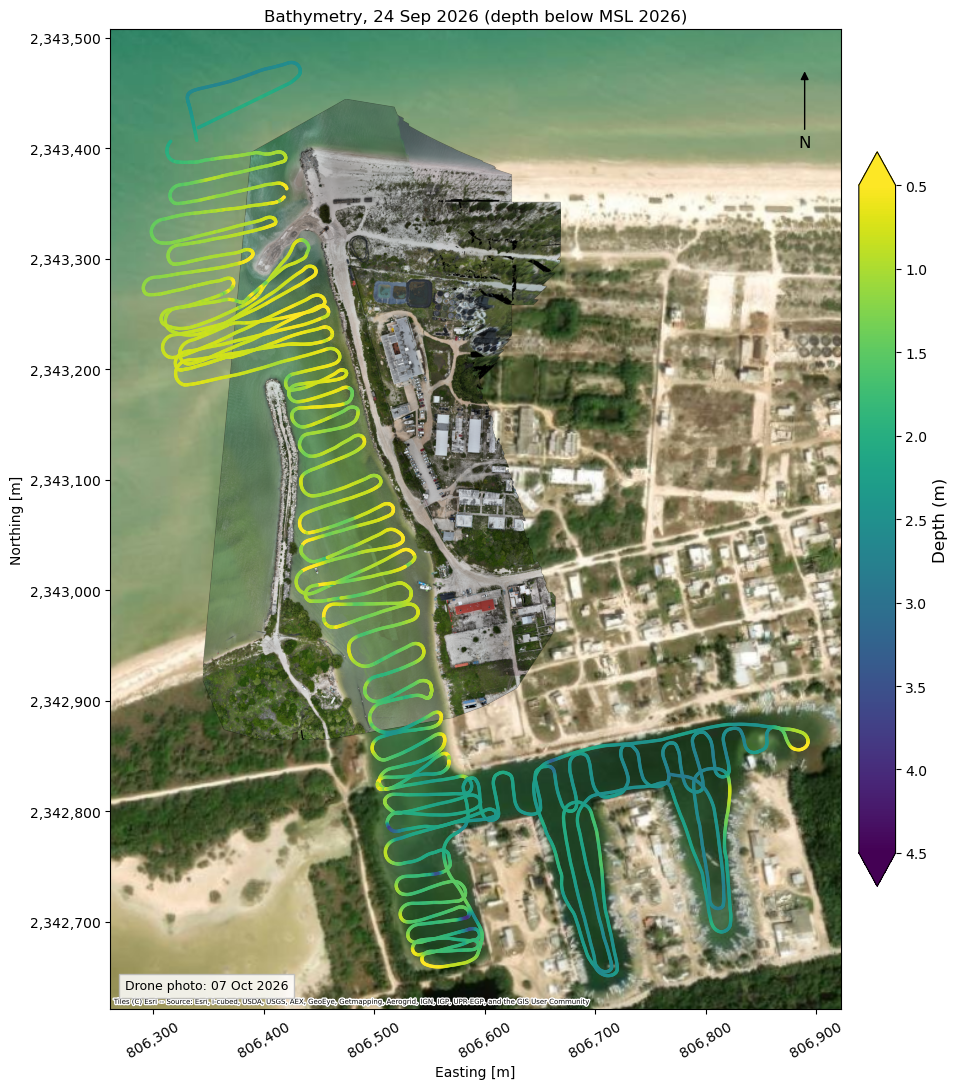

saved output/figures/bathymetry_map_24sep2026.png


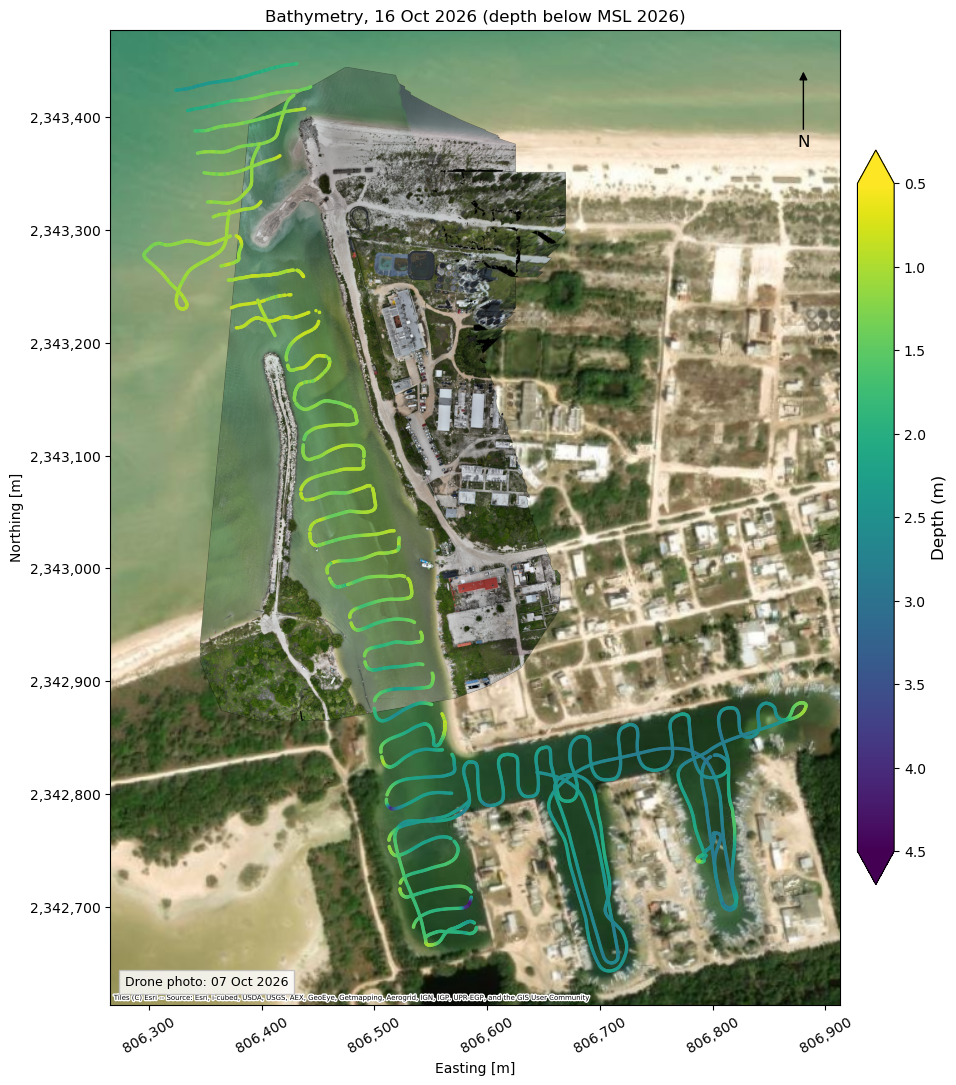

saved output/figures/bathymetry_map_16oct2026.png


In [9]:
OCT_NOTE = " (depth below MSL 2026)" if OCT_TIDE_FILE else " (depth below water level at survey start)"
oct_title = "Bathymetry, 16 Oct 2026" + OCT_NOTE
for survey, title, out_png in [(sep, "Bathymetry, 24 Sep 2026 (depth below MSL 2026)", SEP_OUT_PNG), (oct_, oct_title, OCT_OUT_PNG)]:
    fig, ax = plt.subplots(figsize=(10, 11))
    colorbar(draw_map(ax, survey, title, area(survey)), ax)
    plt.tight_layout()
    plt.savefig(out_png, dpi=200)
    plt.show()
    print("saved", out_png)

## Comparison

Same extent and colour scale for both surveys.

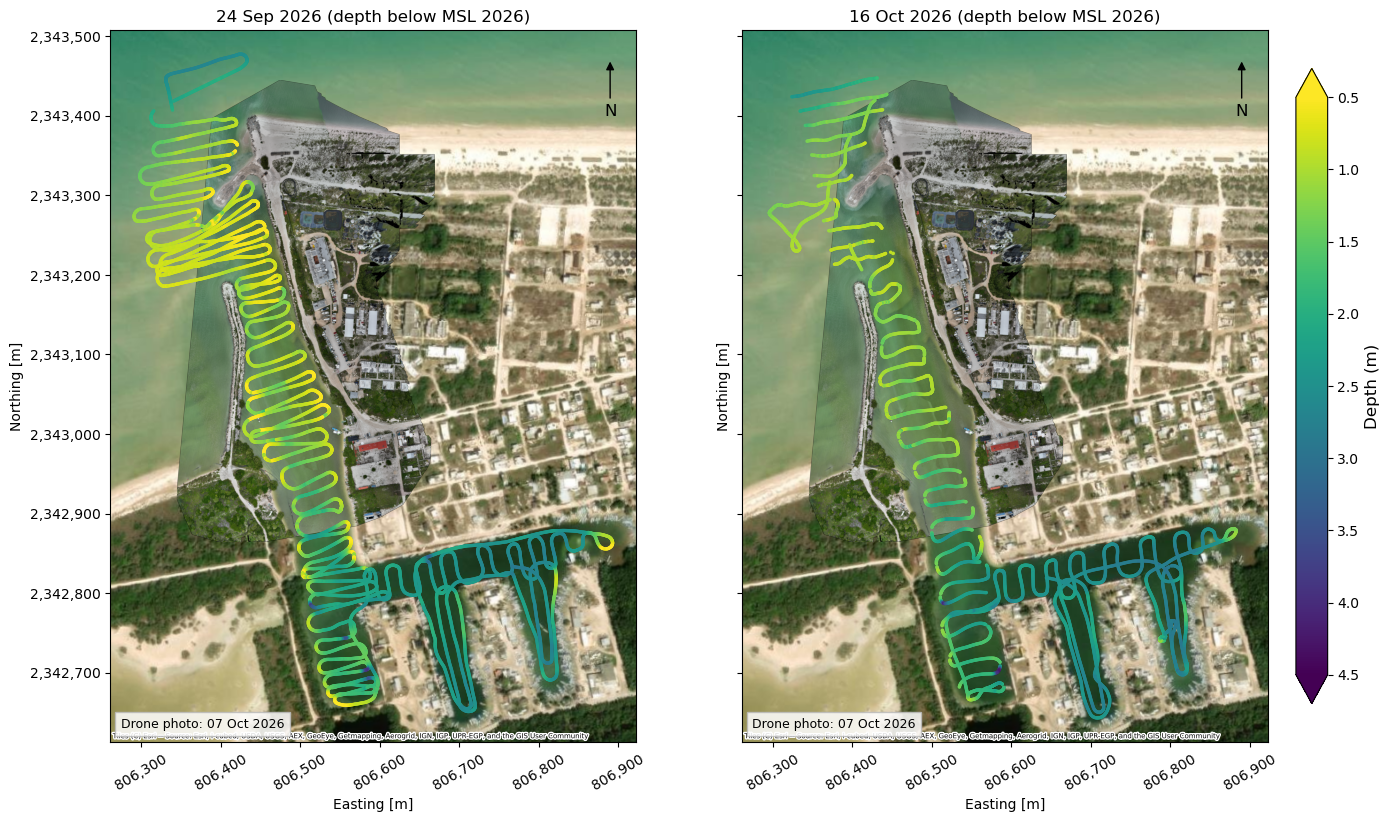

saved output/figures/bathymetry_24sep_vs_16oct.png


In [10]:
extent = area(sep, oct_)
fig, axes = plt.subplots(1, 2, figsize=(18, 11), sharex=True, sharey=True)
draw_map(axes[0], sep, "24 Sep 2026 (depth below MSL 2026)", extent)
sc = draw_map(axes[1], oct_, "16 Oct 2026" + OCT_NOTE, extent)
colorbar(sc, axes)
plt.savefig(COMPARE_PNG, dpi=200, bbox_inches="tight")
plt.show()
print("saved", COMPARE_PNG)

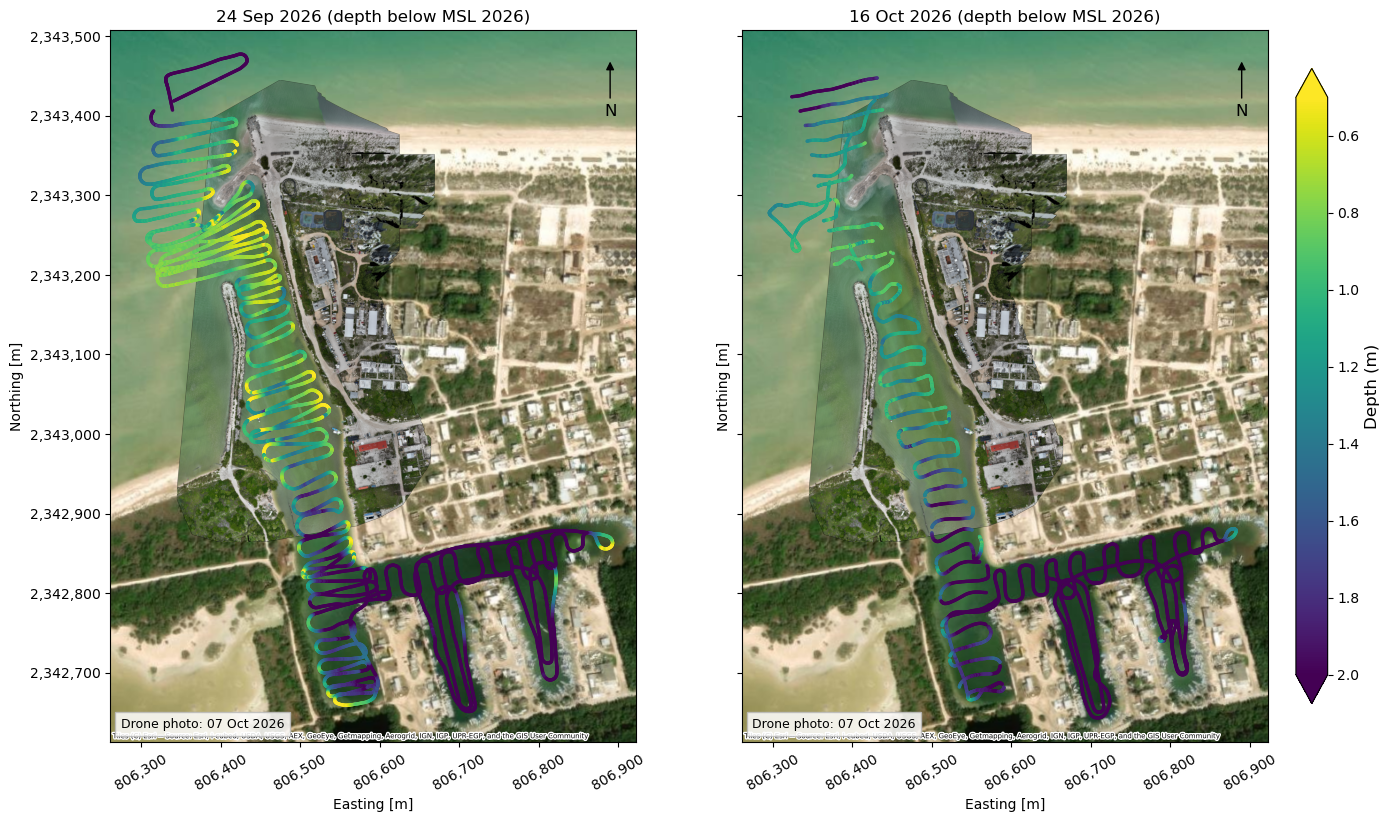

saved output/figures/bathymetry_24sep_vs_16oct_0.5-2m.png


In [11]:
# zoom the colour scale in on the shallow part (0.5-2 m)
SHALLOW_MIN_M, SHALLOW_MAX_M = 0.5, 2.0
COMPARE_SHALLOW_PNG = "output/figures/bathymetry_24sep_vs_16oct_0.5-2m.png"

fig, axes = plt.subplots(1, 2, figsize=(18, 11), sharex=True, sharey=True)
draw_map(axes[0], sep, "24 Sep 2026 (depth below MSL 2026)", extent, vmin=SHALLOW_MIN_M, vmax=SHALLOW_MAX_M)
sc = draw_map(axes[1], oct_, "16 Oct 2026" + OCT_NOTE, extent, vmin=SHALLOW_MIN_M, vmax=SHALLOW_MAX_M)
colorbar(sc, axes)
plt.savefig(COMPARE_SHALLOW_PNG, dpi=200, bbox_inches="tight")
plt.show()
print("saved", COMPARE_SHALLOW_PNG)

## Difference 16 Oct - 24 Sep

Both surveys are gridded on 2 m cells (median per cell) and only cells with data in both surveys are used.
Positive (blue) = deeper on 16 Oct, so erosion. Negative (red) = shallower, so deposition.
Differences of a few cm are within the error (different sounders, tide reference).

689 cells of 2 m in both surveys (2,756 m2)
change: mean +0.14 m, median +0.14 m, middle 90% -0.01 to +0.31 m
deeper by > 0.2 m: 20% of cells | shallower by > 0.2 m: 0% of cells
saved output/bathymetry_difference_16oct_minus_24sep.csv


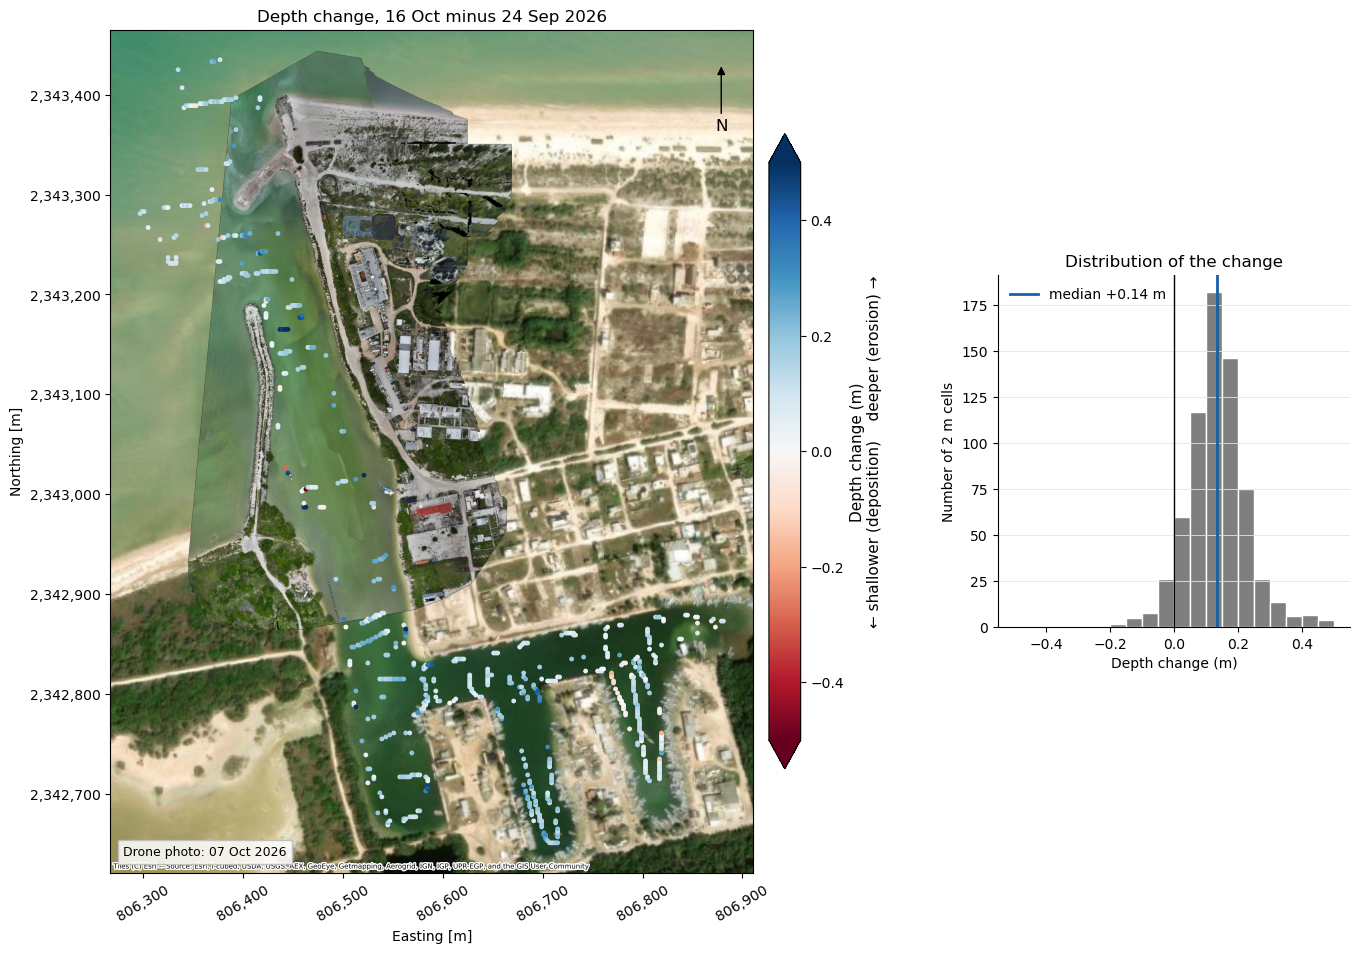

saved output/figures/bathymetry_difference_16oct_minus_24sep.png


In [12]:
def gridded(survey):
    cells = survey.assign(i=np.floor(survey["X"] / DIFF_CELL_M), j=np.floor(survey["Y"] / DIFF_CELL_M))
    return cells.groupby(["i", "j"])["depth_m"].median()

diff = pd.concat({"depth_24sep_m": gridded(sep), "depth_16oct_m": gridded(oct_)}, axis=1, join="inner").reset_index()
diff["X"] = (diff["i"] + 0.5) * DIFF_CELL_M
diff["Y"] = (diff["j"] + 0.5) * DIFF_CELL_M
diff["change_m"] = diff["depth_16oct_m"] - diff["depth_24sep_m"]
diff = diff[["X", "Y", "depth_24sep_m", "depth_16oct_m", "change_m"]]
diff.round(3).to_csv(DIFF_CSV, index=False)

ch = diff["change_m"]
print(f"{len(diff)} cells of {DIFF_CELL_M:g} m in both surveys ({len(diff) * DIFF_CELL_M**2:,.0f} m2)")
print(f"change: mean {ch.mean():+.2f} m, median {ch.median():+.2f} m, middle 90% {ch.quantile(0.05):+.2f} to {ch.quantile(0.95):+.2f} m")
print(f"deeper by > 0.2 m: {(ch > 0.2).mean():.0%} of cells | shallower by > 0.2 m: {(ch < -0.2).mean():.0%} of cells")
print("saved", DIFF_CSV)

fig, (ax, axh) = plt.subplots(1, 2, figsize=(16, 11), gridspec_kw=dict(width_ratios=[2.2, 1]))
sc = draw_map(ax, diff, "Depth change, 16 Oct minus 24 Sep 2026", area(diff), value="change_m", cmap="RdBu",
              vmin=-DIFF_LIMIT_M, vmax=DIFF_LIMIT_M, size=POINT_SIZE * 2)
cb = plt.colorbar(sc, ax=ax, shrink=0.75, pad=0.02, extend="both")
cb.set_label("Depth change (m)\n← shallower (deposition)    deeper (erosion) →", fontsize=11)

# histogram
bins = np.arange(-DIFF_LIMIT_M, DIFF_LIMIT_M + 0.05, 0.05)
axh.hist(ch.clip(-DIFF_LIMIT_M, DIFF_LIMIT_M), bins=bins, color="#7f7f7f", edgecolor="white", linewidth=1)
axh.axvline(0, color="black", lw=1)
axh.axvline(ch.median(), color="#185FA5", lw=2, label=f"median {ch.median():+.2f} m")
axh.set_xlabel("Depth change (m)")
axh.set_ylabel(f"Number of {DIFF_CELL_M:g} m cells")
axh.set_title("Distribution of the change", fontsize=12)
axh.spines[["top", "right"]].set_visible(False)
axh.grid(axis="y", color="#E5E4DF", lw=0.6)
axh.legend(frameon=False)
axh.set_box_aspect(1)

plt.savefig(DIFF_PNG, dpi=200, bbox_inches="tight")
plt.show()
print("saved", DIFF_PNG)


## Drone photo export

Saves the drone photo as a png. Scale 1 is full resolution (17391 x 31111 px, ~630 MB, takes around 8 min), 2 or 4 makes it smaller. Skipped if the file is already there. Needs the original tif (`DRONE_TIF`), which is not in the repository, so without it only the preview is shown.

DRONE_TIF not set, no export


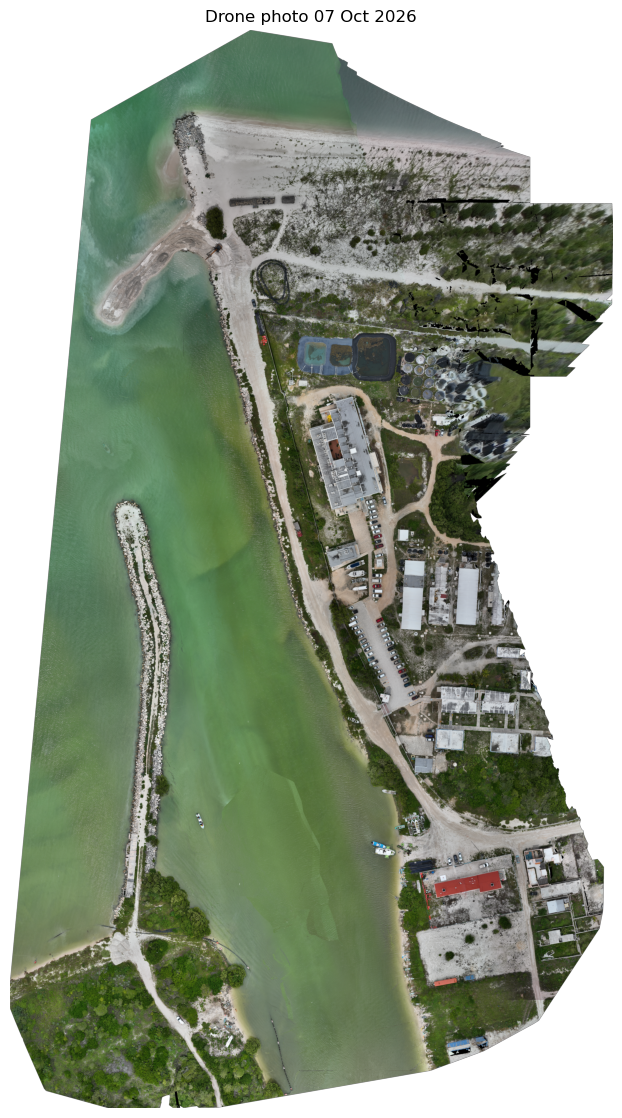

In [13]:
DRONE_EXPORT_SCALE = 1      # 1 = full res, 2 = half, 4 = quarter

import rasterio, rasterio.shutil
from rasterio.enums import Resampling

name = "full_resolution" if DRONE_EXPORT_SCALE == 1 else f"1_{DRONE_EXPORT_SCALE}"
out = os.path.join(FIG_DIR, f"drone_photo_{drone_date:%d%b%Y}_{name}.png".lower())
if not DRONE_TIF:
    print("DRONE_TIF not set, no export")
elif os.path.exists(out):
    print("already made:", out)
elif DRONE_EXPORT_SCALE == 1:
    rasterio.shutil.copy(DRONE_TIF, out, driver="PNG")
    print("saved", out)
else:
    with rasterio.open(DRONE_TIF) as src:
        img = src.read(out_shape=(src.count, src.height // DRONE_EXPORT_SCALE, src.width // DRONE_EXPORT_SCALE),
                       resampling=Resampling.average)
    plt.imsave(out, np.moveaxis(img, 0, -1))
    print("saved", out)

# preview (low res version)
if drone is not None:
    plt.figure(figsize=(8, 14))
    plt.imshow(drone)
    plt.axis("off")
    plt.title(f"Drone photo {drone_date:%d %b %Y}")
    plt.show()


## Tide plots

For the report: the full tide record and just the survey day.

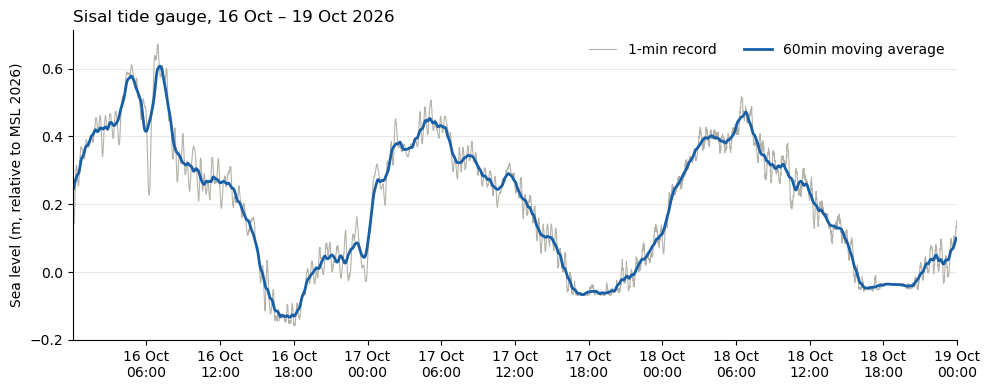

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

TIDE_FILE   = "data/tide/20261016al18_sisal.txt"
UTC_TO_LOCAL = 0
SMOOTH      = "60min"
SAVE        = False   # png + pdf for the report
OFFSET = 1.9          # MSL 2026

tide = pd.read_csv(TIDE_FILE, sep=r"\s+", header=None,
                   names=["Y", "M", "D", "h", "m", "s", "level"])
tide["time"] = pd.to_datetime(dict(year=tide.Y, month=tide.M, day=tide.D,
                                   hour=tide.h, minute=tide.m, second=tide.s))
tide["time"] += pd.Timedelta(hours=UTC_TO_LOCAL)
tide = tide.set_index("time")["level"] - OFFSET
tide_smooth = tide.rolling(SMOOTH, center=True).mean()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(tide.index, tide, color="#B4B2A9", lw=0.8, label="1-min record")
ax.plot(tide_smooth.index, tide_smooth, color="#185FA5", lw=2,
        label=f"{SMOOTH} moving average")

ax.set_ylabel("Sea level (m, relative to MSL 2026)")
ax.set_title(f"Sisal tide gauge, {tide.index[0]:%d %b} – {tide.index[-1]:%d %b %Y}", loc="left")
ax.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 6, 12, 18]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M"))
ax.set_xlim(tide.index[0], tide.index[-1])
ax.grid(axis="y", color="#E5E4DF", lw=0.6)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper right", ncol=2)
fig.tight_layout()

if SAVE:
    name = "output/figures/sisal_tide"
    fig.savefig(f"{name}.png", dpi=200)
    fig.savefig(f"{name}.pdf")
plt.show()

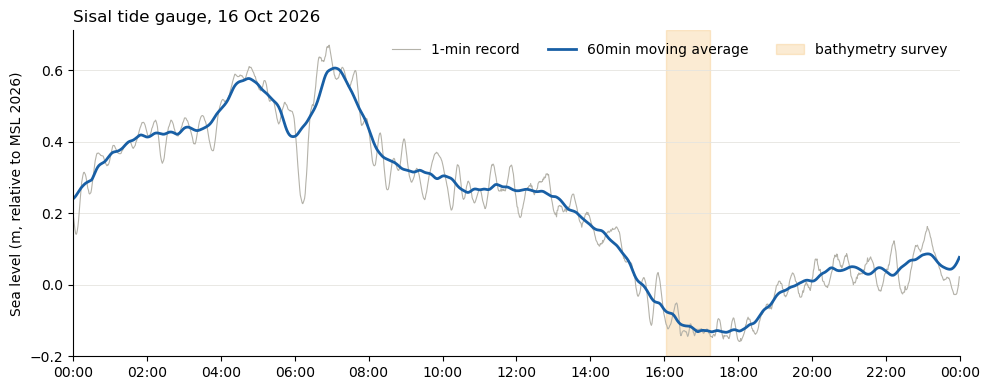

In [15]:
# only 16 Oct
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

TIDE_FILE = "data/tide/20261016al18_sisal.txt"
DAY    = "2026-10-16"
OFFSET = 1.9
SMOOTH = "60min"
SAVE   = False

raw = pd.read_csv(TIDE_FILE, sep=r"\s+", header=None, names=["Y", "M", "D", "h", "m", "s", "level"])
time = pd.to_datetime(dict(year=raw.Y, month=raw.M, day=raw.D, hour=raw.h, minute=raw.m, second=raw.s))
tide16 = pd.Series(raw["level"].values - OFFSET, index=time).sort_index()
tide16_smooth = tide16.rolling(SMOOTH, center=True).mean()
day, day_smooth = tide16.loc[DAY], tide16_smooth.loc[DAY]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(day.index, day, color="#B4B2A9", lw=0.8, label="1-min record")
ax.plot(day_smooth.index, day_smooth, color="#185FA5", lw=2, label=f"{SMOOTH} moving average")
if "oct_" in globals():   # shade the survey time
    ax.axvspan(oct_["time"].min(), oct_["time"].max(), color="#EF9F27", alpha=0.2, label="bathymetry survey")

ax.set_ylabel("Sea level (m, relative to MSL 2026)")
ax.set_title(f"Sisal tide gauge, {pd.Timestamp(DAY):%d %b %Y}", loc="left")
ax.xaxis.set_major_locator(mdates.HourLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.set_xlim(pd.Timestamp(DAY), pd.Timestamp(DAY) + pd.Timedelta(days=1))
ax.grid(axis="y", color="#E5E4DF", lw=0.6)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper right", ncol=3)
fig.tight_layout()

if SAVE:
    fig.savefig("output/figures/sisal_tide_16oct.png", dpi=200)
    fig.savefig("output/figures/sisal_tide_16oct.pdf")
plt.show()